# MODEL: MobileNetV2
TASK : Crop Pest and Disease Detection - End-to-End Pipeline
Paste each CELL block into a separate cell in your Jupyter Notebook.
Run cells in order from top to bottom.

---


### Digital Image Processing Concepts Used in This Model

In digital image processing (DIP) for agricultural automation, crop pest and disease detection requires extracting discriminative spatial, chromatic, and textural signatures from raw pixel arrays. Foliar infections (such as bacterial leaf blight, viral mosaic mottle, and fungal leaf spot) induce localized tissue breakdown, producing characteristic chlorotic halos and necrotic centers.

#### Why Crop Images Require Preprocessing
1. **Uncontrolled Illumination:** Field imagery captured under natural sunlight suffers from harsh specular reflections, deep shadow occlusions, and variable diurnal color temperatures.
2. **Camera Distance and Angle:** Handheld smartphones and agricultural drones capture crops from non-uniform working distances and perspectives.
3. **Complex Agricultural Backgrounds:** Soil backgrounds, dried twigs, and overlapping healthy leaves introduce high-frequency background clutter.
4. **Sensor Variations:** Different mobile camera sensors introduce varying noise profiles and dynamic ranges.

#### Spatial and Intensity Transformations in Training
- **Geometric Transformations:** Random horizontal/vertical reflections, affine rotations, and zoom scaling enforce rotational and scale invariance.
- **Intensity Transformations:** Contrast adjustment and brightness scaling simulate shifting daylight intensity without modifying lesion geometry.

#### MobileNetV2: Efficient Spatial Filtering via Depthwise Separable Convolutions
Traditional DIP filters and standard CNN convolutions apply 3D spatial-channel kernels that compute spatial and channel correlations simultaneously. MobileNetV2 factorizes standard convolution into two distinct steps:
1. **Depthwise Convolution:** Performs 2D spatial filtering per input channel independently (retaining spatial gradient patterns).
2. **Pointwise Convolution:** Applies $1 \times 1$ linear projections to compute cross-channel linear combinations.

This factorization drastically reduces floating-point operations (FLOPs) and memory access, making MobileNetV2 optimal for real-time edge processing on smartphones and field scouting hardware.

#### End-to-End DIP & Classification Pipeline
$$\text{Input Image } (H \times W \times 3) \longrightarrow \text{Image Decoding \& Resizing } (224 \times 224) \longrightarrow \text{Data Augmentation } \longrightarrow \text{MobileNet Preprocessing } [-1, 1] \longrightarrow \text{Depthwise Separable Feature Extraction } \longrightarrow \text{Global Pooling } \longrightarrow \text{Dense Classification}$$

> **Important Case Study Note:** This model performs **whole-image classification** (categorizing the overall image into one of 22 pest/disease classes) rather than explicit **semantic pixel segmentation** (which would delineate exact boundary contours for each diseased lesion).

### CELL 1 ── Install Dependencies


In [1]:
!pip install -q split-folders scikit-learn seaborn matplotlib tensorflow

### CELL 2 ── Imports


In [13]:
import os
import warnings
import splitfolders
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU Available: []


### CELL 3 ── Verify & Load Local Dataset  (70 / 15 / 15)


In [14]:
# ==============================================================================
# DATASET PATH CONFIGURATION (Local Dataset in this folder)
# ==============================================================================
# The dataset is stored locally in this project directory.
# - 'Dataset_Split': contains pre-split train (70%), val (15%), and test (15%) sets
# - 'dataset': contains the raw unsplit 22 disease/pest class folders

def resolve_path(folder_name):
    """Resolve local dataset folder path in the project workspace."""
    candidates = [
        folder_name,
        os.path.join(os.getcwd(), folder_name),
        os.path.join(os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else ".", folder_name),
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return folder_name

SPLIT_DIR = resolve_path("Dataset_Split")
RAW_DIR   = resolve_path("dataset")

if os.path.exists(SPLIT_DIR):
    print(f"[OK] Using local split dataset from: '{SPLIT_DIR}'")
elif os.path.exists(RAW_DIR):
    print(f"[NOTE] 'Dataset_Split' not found. Splitting local dataset from: '{RAW_DIR}' (70/15/15)...")
    splitfolders.ratio(RAW_DIR, output=SPLIT_DIR, seed=42, ratio=(0.70, 0.15, 0.15), group_prefix=None)
    print("[OK] Split complete.")
else:
    raise FileNotFoundError(
        f"Dataset not found in this folder! Looked for '{SPLIT_DIR}' and '{RAW_DIR}'. "
        "Please ensure the dataset folder is located in the project directory."
    )

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "val")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

print(f"  --> Train path : {TRAIN_DIR}")
print(f"  --> Val path   : {VAL_DIR}")
print(f"  --> Test path  : {TEST_DIR}")


[OK] Using local split dataset from: 'Dataset_Split'
  --> Train path : Dataset_Split\train
  --> Val path   : Dataset_Split\val
  --> Test path  : Dataset_Split\test


### DIP: Digital Image Representation, Decoding, and Spatial Resizing

#### Digital Color Image Representation
A digital color photograph is represented as a 3D numerical matrix of shape $(H \times W \times 3)$, where $H$ is the image height, $W$ is the image width, and 3 denotes the primary color channels: **Red (R), Green (G), and Blue (B)**. Each pixel intensity is stored as an 8-bit unsigned integer ($uint8$) with discrete intensity levels $\in [0, 255]$.

#### Image Decoding
Stored JPEG files are compressed using Discrete Cosine Transform (DCT) quantization. During dataset loading, TensorFlow decodes the binary compressed bitstream into uncompressed 3D numerical arrays of pixel values.

#### Image Resizing and Spatial Downsampling
Batched tensor processing requires fixed, uniform spatial dimensions across all samples:
- **MobileNetV2 Standard Resolution:** Input images are resized to **$224 \times 224$ pixels**.
- **Computational Trade-Off:** Resizing standardizes camera captures of varying resolutions into $224 \times 224 \times 3 = 150,528$ values, balancing computational efficiency with structural fidelity.
- **Resolution Loss:** Downsampling high-resolution images can blur subtle early-stage fungal pustules or faint leaf miner tracks.
- **Aspect Ratio Distortion:** Direct bilinear downsampling to a square without padding may stretch non-square camera frames.

### CELL 4 ── Hyper-parameters & Data Loaders


In [15]:
BATCH_SIZE = 32
IMG_SIZE   = (224, 224)
EPOCHS     = 25
SEED       = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)          # keep order for confusion matrix

CLASS_NAMES  = train_ds.class_names
NUM_CLASSES  = len(CLASS_NAMES)
print(f"Classes  ({NUM_CLASSES}): {CLASS_NAMES}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 17568 files belonging to 22 classes.
Found 3761 files belonging to 22 classes.
Found 3795 files belonging to 22 classes.
Classes  (22): ['Cashew anthracnose', 'Cashew gumosis', 'Cashew healthy', 'Cashew leaf miner', 'Cashew red rust', 'Cassava bacterial blight', 'Cassava brown spot', 'Cassava green mite', 'Cassava healthy', 'Cassava mosaic', 'Maize fall armyworm', 'Maize grasshoper', 'Maize healthy', 'Maize leaf beetle', 'Maize leaf blight', 'Maize leaf spot', 'Maize streak virus', 'Tomato healthy', 'Tomato leaf blight', 'Tomato leaf curl', 'Tomato septoria leaf spot', 'Tomato verticulium wilt']


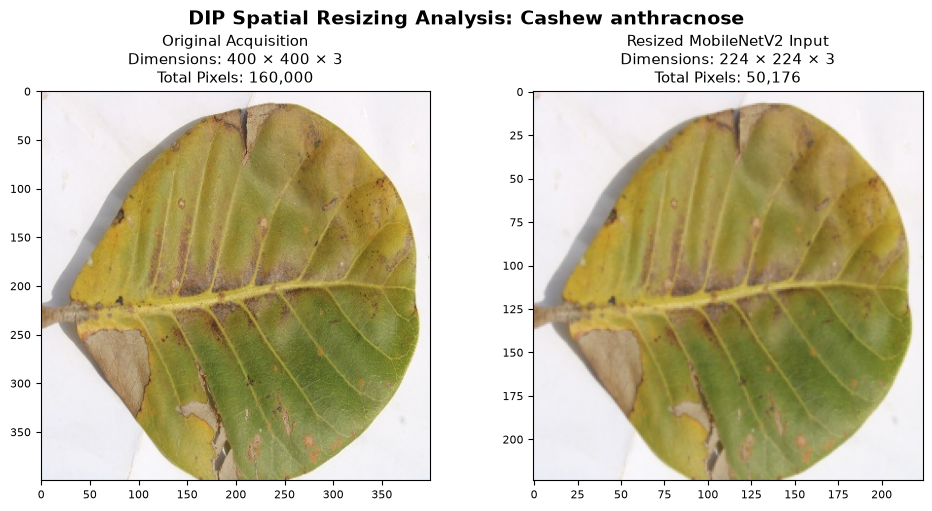

Spatial reduction ratio: 3.19x fewer pixels.


In [16]:
# DIP VISUALIZATION: Original Image vs. Resized Model Input (224x224)
import glob
from PIL import Image

sample_search = glob.glob(os.path.join(TRAIN_DIR, "*", "*.jpg"))
if sample_search:
    sample_file_path = sample_search[0]
    class_folder_name = os.path.basename(os.path.dirname(sample_file_path))
    
    orig_img = Image.open(sample_file_path)
    orig_w, orig_h = orig_img.size
    resized_img = orig_img.resize(IMG_SIZE, Image.BILINEAR)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f"DIP Spatial Resizing Analysis: {class_folder_name}", fontsize=14, fontweight="bold")
    
    axes[0].imshow(orig_img)
    axes[0].set_title(f"Original Acquisition\nDimensions: {orig_h} × {orig_w} × 3\nTotal Pixels: {orig_h * orig_w:,}", fontsize=11)
    axes[0].axis("on"); axes[0].tick_params(labelsize=8)
    
    axes[1].imshow(resized_img)
    axes[1].set_title(f"Resized MobileNetV2 Input\nDimensions: {IMG_SIZE[1]} × {IMG_SIZE[0]} × 3\nTotal Pixels: {IMG_SIZE[0] * IMG_SIZE[1]:,}", fontsize=11)
    axes[1].axis("on"); axes[1].tick_params(labelsize=8)
    
    plt.tight_layout()
    plt.show()
    print(f"Spatial reduction ratio: {(orig_h * orig_w) / (IMG_SIZE[0] * IMG_SIZE[1]):.2f}x fewer pixels.")
else:
    print("No images found for resizing demonstration.")

### CELL 5 ── Explore: Sample Images from Each Split


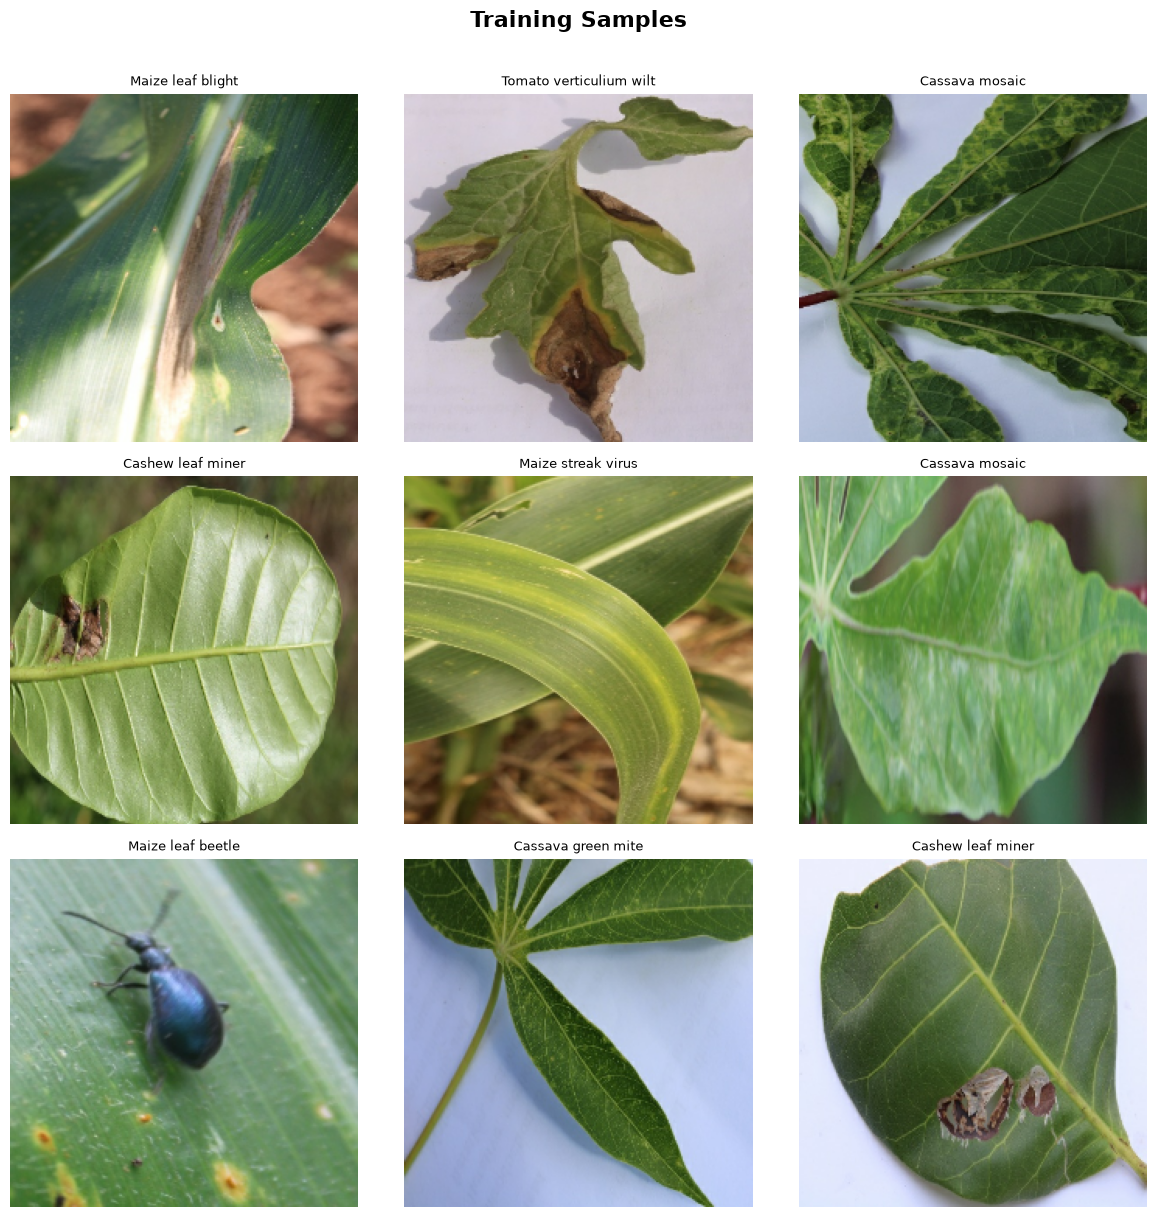

In [17]:
def plot_samples(dataset, class_names, title, n=9):
    plt.figure(figsize=(12, 12))
    plt.suptitle(title, fontsize=16, fontweight="bold", y=1.01)
    for images, labels in dataset.take(1):
        for i in range(min(n, len(images))):
            ax = plt.subplot(3, 3, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(class_names[labels[i]], fontsize=9)
            plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_samples(train_ds, CLASS_NAMES, "Training Samples")

### CELL 6 ── Class Distribution Bar Chart


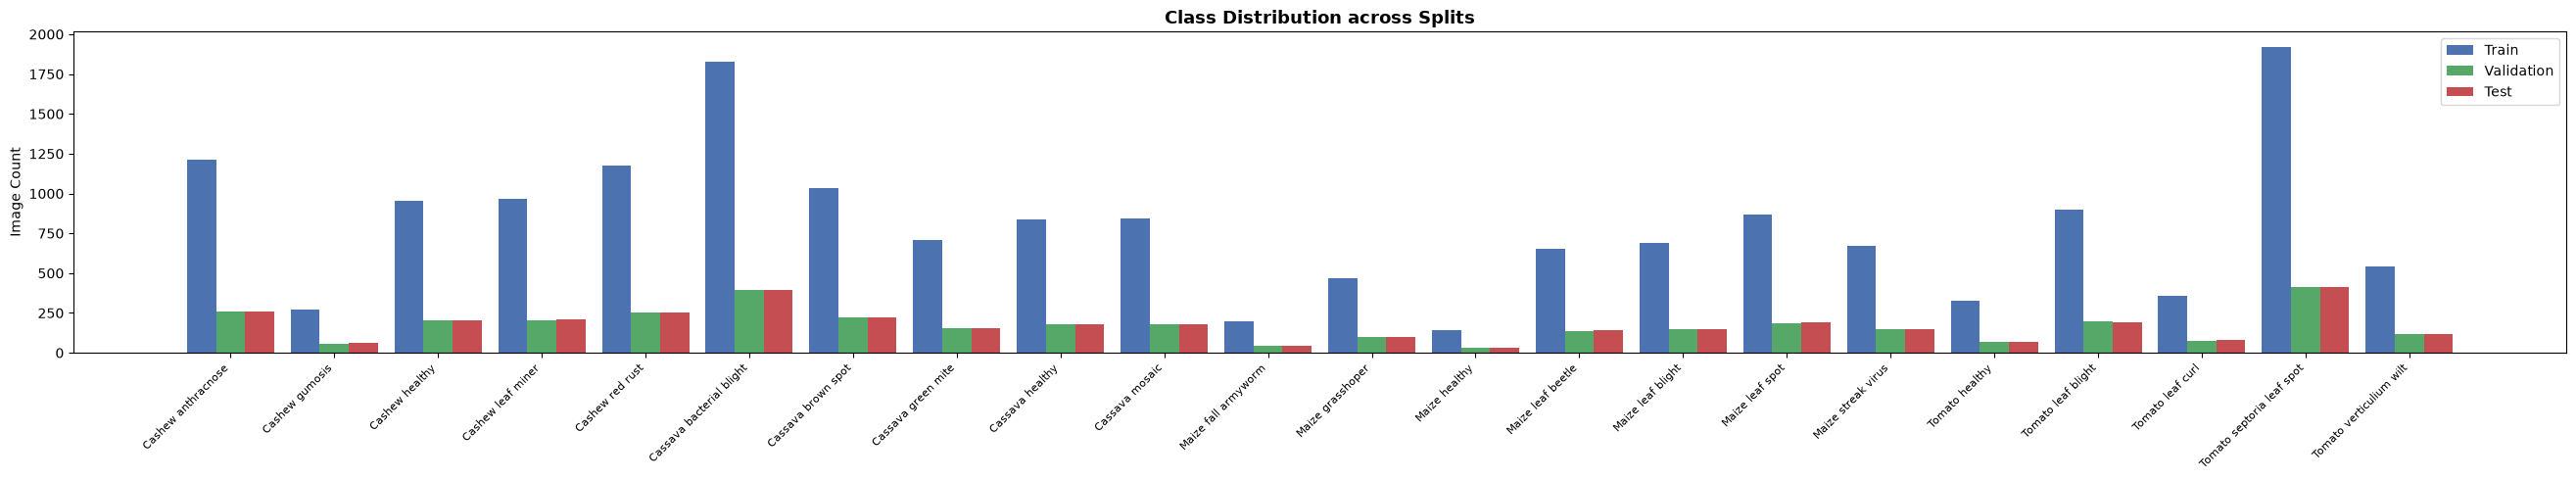

In [18]:
def count_classes(directory, class_names):
    counts = [len(os.listdir(os.path.join(directory, c))) for c in class_names]
    return counts

train_counts = count_classes(TRAIN_DIR, CLASS_NAMES)
val_counts   = count_classes(VAL_DIR,   CLASS_NAMES)
test_counts  = count_classes(TEST_DIR,  CLASS_NAMES)

x = np.arange(len(CLASS_NAMES))
width = 0.28

fig, ax = plt.subplots(figsize=(max(12, NUM_CLASSES * 1.2), 5))
ax.bar(x - width, train_counts, width, label="Train",      color="#4C72B0")
ax.bar(x,         val_counts,   width, label="Validation",  color="#55A868")
ax.bar(x + width, test_counts,  width, label="Test",        color="#C44E52")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_title("Class Distribution across Splits", fontsize=13, fontweight="bold")
ax.set_ylabel("Image Count")
ax.legend()
plt.tight_layout()
plt.show()

### DIP: Geometric and Intensity Transformations

Data augmentation applies digital image processing transformations to synthetic training images, expanding effective dataset variance and enforcing invariance to camera orientation and field illumination.

#### 1. Geometric Transformations (Spatial Coordinate Remapping)
Geometric transformations alter the spatial coordinates $(x, y)$ of image pixels via 2D spatial mapping functions $I'(x', y') = I(T_x(x, y), T_y(x, y))$:
- **Spatial Reflection (Flipping):** `RandomFlip("horizontal_and_vertical")` reflects pixels across horizontal ($y' = H - y$) and vertical ($x' = W - x$) axes. Foliar diseases possess no fixed gravitational orientation.
- **Rotation:** `RandomRotation(0.25)` applies 2D affine rotation. In Keras, a factor of **$0.25$ represents a fraction of $2\pi$**, meaning images are randomly rotated within $[-0.25 \times 360^\circ, +0.25 \times 360^\circ] = [-90^\circ, +90^\circ]$ (a full quarter turn), **not** 25 degrees.
- **Scaling (Zoom):** `RandomZoom(0.20)` scales coordinates by $\pm 20\%$, simulating variable camera distances.

#### 2. Intensity Transformations (Radiometric Point Operations)
Intensity transformations modify pixel intensity values directly without altering spatial pixel geometry:
- **Contrast Adjustment:** `RandomContrast(0.15)` dynamically stretches or compresses the image dynamic range around its mean intensity: $I'(x,y) = \bar{I} + c \cdot (I(x,y) - \bar{I})$, simulating variable ambient daylight and cloud cover.
- **Brightness Adjustment:** `RandomBrightness(0.10)` shifts intensity levels additively: $I'(x,y) = I(x,y) + \delta$, simulating overexposure or deep canopy shading.

### CELL 7 ── Data Augmentation Pipeline


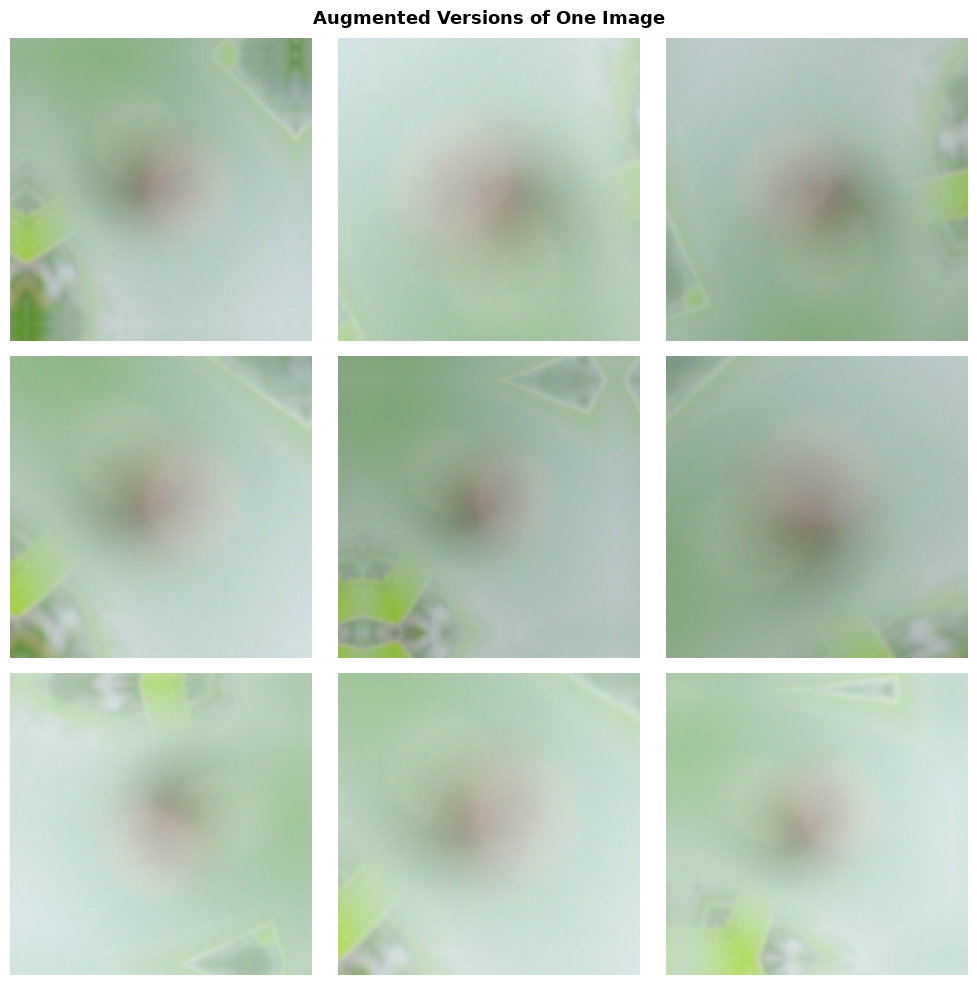

In [19]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.20),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10),
], name="augmentation")

# Visualise augmentation on one image
for images, _ in train_ds.take(1):
    sample = images[0]
aug_samples = [data_augmentation(tf.expand_dims(sample, 0))[0] for _ in range(9)]

plt.figure(figsize=(10, 10))
plt.suptitle("Augmented Versions of One Image", fontsize=13, fontweight="bold")
for i, img in enumerate(aug_samples):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.axis("off")
plt.tight_layout()
plt.show()

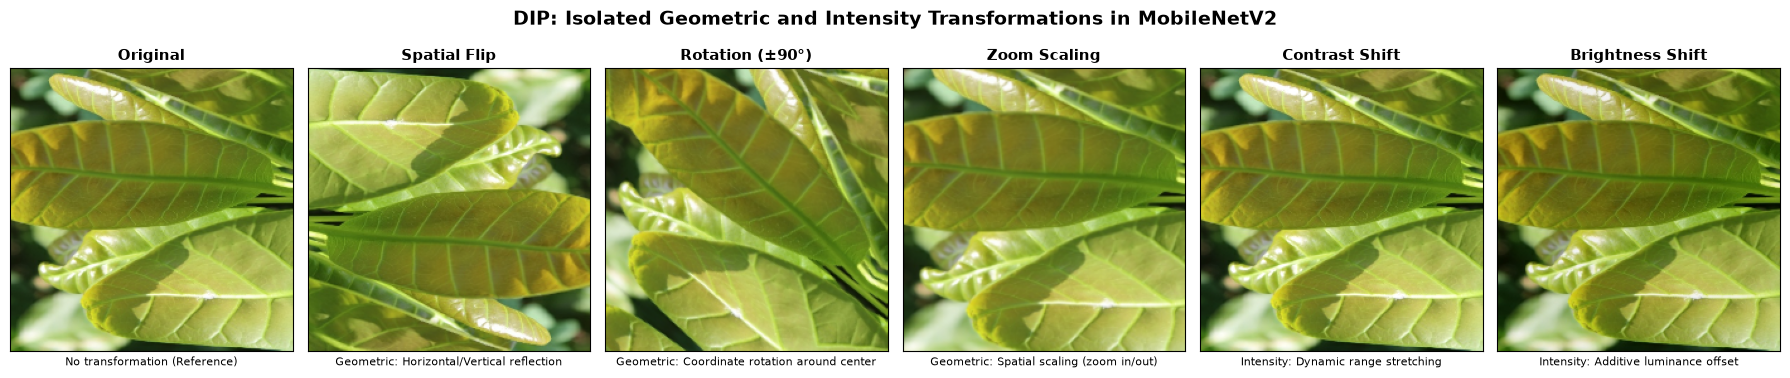

In [20]:
# DIP VISUALIZATION: Individual Geometric and Intensity Transformations Applied Separately
for images, _ in train_ds.take(1):
    base_sample = images[0]
    break

t_flip = layers.RandomFlip("horizontal_and_vertical", seed=42)
t_rot  = layers.RandomRotation(0.25, seed=42)            # +/- 90 degrees
t_zoom = layers.RandomZoom(0.20, seed=42)                # +/- 20% zoom
t_cont = layers.RandomContrast(0.15, seed=42)            # +/- 15% contrast
t_brit = layers.RandomBrightness(0.10, value_range=(0, 255), seed=42) # +/- 10% brightness

sample_tensor = tf.expand_dims(base_sample, 0)

transforms_list = [
    ("Original", base_sample.numpy().astype("uint8"), "No transformation (Reference)"),
    ("Spatial Flip", t_flip(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Horizontal/Vertical reflection"),
    ("Rotation (±90°)", t_rot(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Coordinate rotation around center"),
    ("Zoom Scaling", t_zoom(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Spatial scaling (zoom in/out)"),
    ("Contrast Shift", t_cont(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Dynamic range stretching"),
    ("Brightness Shift", t_brit(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Additive luminance offset"),
]

fig, axes = plt.subplots(1, 6, figsize=(18, 3.8))
fig.suptitle("DIP: Isolated Geometric and Intensity Transformations in MobileNetV2", fontsize=14, fontweight="bold")

for ax, (title, img_trans, desc) in zip(axes, transforms_list):
    ax.imshow(img_trans)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(desc, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

### DIP: Convolutional Filtering and Hierarchical Feature Extraction

#### Mathematical Formulation of 2D Spatial Convolution
In discrete 2D digital image processing, spatial filtering correlates an input feature map $X$ with a 2D filter kernel $K$ of spatial dimensions $M \times N$:

$$Y(i, j) = (X * K)(i, j) = \sum_{m=-M/2}^{M/2} \sum_{n=-N/2}^{N/2} K(m, n) \cdot X(i + m, j + n)$$

#### MobileNetV2: Depthwise Separable Convolutions & Inverted Residuals
Standard convolution convolves all $C_{in}$ channels simultaneously with $C_{out}$ kernels of size $D_K \times D_K \times C_{in}$, requiring $D_K^2 \cdot C_{in} \cdot C_{out} \cdot H \cdot W$ multiplications.

MobileNetV2 splits this into:
1. **Depthwise Convolution ($3 \times 3$):** Applies a single $3 \times 3$ spatial filter to each input channel independently:
   $$Y_{depthwise}(i, j, c) = \sum_{m, n} K_c(m, n) \cdot X(i+m, j+n, c)$$
   Computes pure spatial filtering without cross-channel mixing.
2. **Pointwise Convolution ($1 \times 1$):** Applies $1 \times 1$ convolutions across all channels:
   $$Y_{pointwise}(i, j, k) = \sum_c W(c, k) \cdot Y_{depthwise}(i, j, c)$$
   Computes linear cross-channel combinations.

**Computational Efficiency Gain:**
$$\frac{\text{Depthwise Separable Cost}}{\text{Standard Conv Cost}} = \frac{D_K^2 \cdot C_{in} + C_{in} \cdot C_{out}}{D_K^2 \cdot C_{in} \cdot C_{out}} = \frac{1}{C_{out}} + \frac{1}{D_K^2} \approx \frac{1}{9}$$
This represents an **$8$ to $9\times$ reduction in spatial computational cost** with minimal accuracy degradation.

3. **Inverted Residuals with Linear Bottlenecks:** Thin bottleneck layers are expanded to high-dimensional representations for non-linear depthwise filtering, then projected back to low-dimensional space with linear activations, preventing non-linearities from destroying manifold details.

---

### DIP: Pixel Intensity Preprocessing

| Model | Preprocessing Function | Expected Pixel Range | Output Range |
|---|---|---|---|
| **MobileNetV2** | `tf.keras.applications.mobilenet_v2.preprocess_input` | $[0, 255]$ raw uint8/float32 | $[-1.0, +1.0]$ float32 |

#### Transformation Formula:
$$X_{norm} = \frac{X}{127.5} - 1.0$$
This centers pixel intensities symmetrically around zero ($[0, 255] \to [-1.0, 1.0]$), which accelerates gradient convergence in batch-normalized depthwise layers.

### CELL 8 ── Build MobileNetV2 Transfer Learning Model


In [21]:
base_model = MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False          # freeze backbone

inputs  = tf.keras.Input(shape=IMG_SIZE + (3,))
x       = data_augmentation(inputs)
x       = preprocess_input(x)         # MobileNetV2 expects [-1, 1]
x       = base_model(x, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.BatchNormalization()(x)
x       = layers.Dropout(0.40)(x)
x       = layers.Dense(256, activation="relu",
                        kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x       = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="MobileNetV2_CropDisease")
model.summary()

Model: "MobileNetV2_CropDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,596,694 (9.91 MB)

 Trainable params: 336,150 (1.28 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

### Digital Image Processing vs. Machine Learning in Model Training

- **Image Processing Operations:** Resizing to $224 \times 224$, geometric coordinate transforms (flips, rotations, zooms), pixel intensity normalization to $[-1, 1]$, depthwise 2D spatial filtering, and global spatial average pooling.
- **Machine Learning Operations:** Categorical cross-entropy loss computation, error backpropagation, Adam optimizer weight updates, learning rate reduction on plateaus, transfer learning backbone freezing (Phase 1), and selective layer unfreezing (Phase 2 fine-tuning).

DIP structures the optical signals into informative spatial feature representations; ML discovers the optimal weighting parameters across those representations.

### CELL 9 ── Compile & Train (Phase 1 — frozen backbone)


In [23]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cb_early  = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                    restore_best_weights=True, verbose=1)
cb_lr     = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.4,
                                        patience=2, min_lr=1e-7, verbose=1)
cb_ckpt   = callbacks.ModelCheckpoint("best_mobilenetv2.keras", save_best_only=True,
                                       monitor="val_accuracy", verbose=1)

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt],
    verbose=1,
)
print("Phase-1 training complete.")

Epoch 1/25


549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 564ms/step - accuracy: 0.7030 - loss: 0.9530
Epoch 1: val_accuracy improved from None to 0.76921, saving model to best_mobilenetv2.keras

Epoch 1: finished saving model to best_mobilenetv2.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 393s 684ms/step - accuracy: 0.7030 - loss: 0.9530 - val_accuracy: 0.7692 - val_loss: 0.7117 - learning_rate: 0.0010
Epoch 2/25
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 566ms/step - accuracy: 0.7199 - loss: 0.8608
Epoch 2: val_accuracy improved from 0.76921 to 0.78011, saving model to best_mobilenetv2.keras

Epoch 2: finished saving model to best_mobilenetv2.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 367s 668ms/step - accuracy: 0.7199 - loss: 0.8608 - val_accuracy: 0.7801 - val_loss: 0.6576 - learning_rate: 0.0010
Epoch 3/25
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step - accuracy: 0.7332 - loss: 0.8134
Epoch 3: val_accuracy improved from 0.78011 to 0.78277, saving model to best_mobilenetv2.keras

Epoch 3: finished saving model to best_mobilenetv2.keras
5

### CELL 10 ── Fine-Tuning (Phase 2 — unfreeze top 30 layers)


In [24]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_ft = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt],
    verbose=1,
)
print("Fine-tuning complete.")

# Merge histories for plotting
for k in history.history:
    history.history[k] += history_ft.history.get(k, [])

Epoch 1/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 871ms/step - accuracy: 0.7448 - loss: 0.7986
Epoch 1: val_accuracy did not improve from 0.82930
549/549 ━━━━━━━━━━━━━━━━━━━━ 588s 1s/step - accuracy: 0.7448 - loss: 0.7986 - val_accuracy: 0.8165 - val_loss: 0.6060 - learning_rate: 1.0000e-05
Epoch 2/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7702 - loss: 0.7210
Epoch 2: val_accuracy did not improve from 0.82930
549/549 ━━━━━━━━━━━━━━━━━━━━ 728s 1s/step - accuracy: 0.7702 - loss: 0.7210 - val_accuracy: 0.8240 - val_loss: 0.5757 - learning_rate: 1.0000e-05
Epoch 3/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 715ms/step - accuracy: 0.7869 - loss: 0.6724
Epoch 3: val_accuracy did not improve from 0.82930
549/549 ━━━━━━━━━━━━━━━━━━━━ 443s 806ms/step - accuracy: 0.7869 - loss: 0.6724 - val_accuracy: 0.8248 - val_loss: 0.5636 - learning_rate: 1.0000e-05
Epoch 4/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 701ms/step - accuracy: 0.7902 - loss: 0.6540
Epoch 4: val_accuracy improved from 0.82930 to 0.83143, s

### CELL 11 ── Training Curves


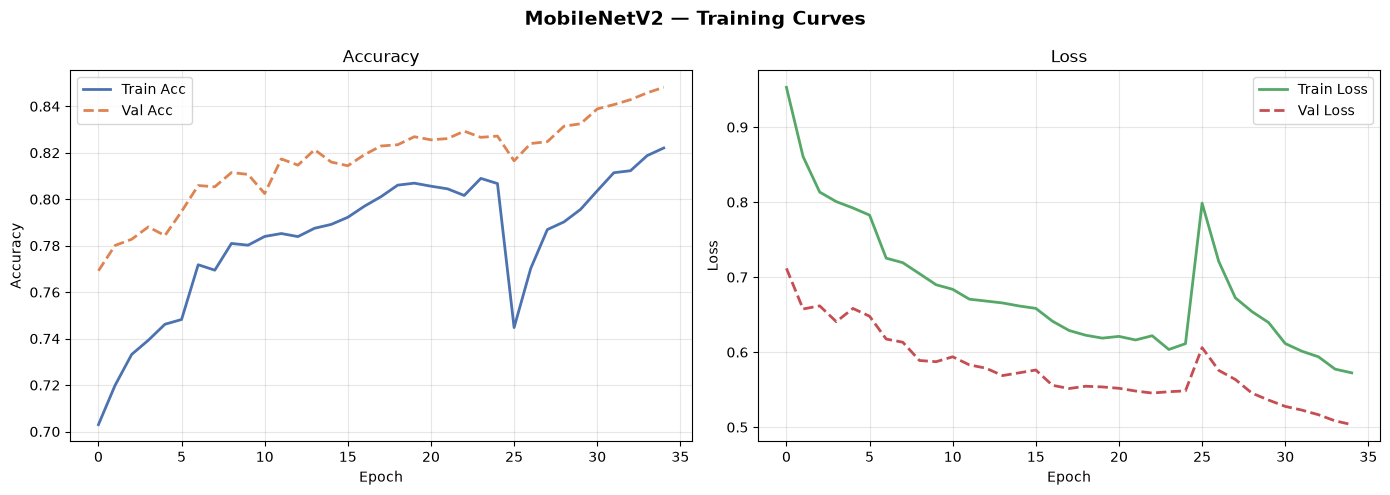

In [25]:
def plot_history(history):
    acc     = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss    = history.history["loss"]
    val_loss= history.history["val_loss"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("MobileNetV2 — Training Curves", fontsize=14, fontweight="bold")

    axes[0].plot(acc,     label="Train Acc",  linewidth=2, color="#4C72B0")
    axes[0].plot(val_acc, label="Val Acc",    linewidth=2, color="#DD8452", linestyle="--")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(loss,     label="Train Loss", linewidth=2, color="#55A868")
    axes[1].plot(val_loss, label="Val Loss",   linewidth=2, color="#C44E52", linestyle="--")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history)

### CELL 12 ── Evaluate on Test Set


In [27]:
model.load_weights("best_mobilenetv2.keras")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy : {test_acc * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")


119/119 ━━━━━━━━━━━━━━━━━━━━ 66s 546ms/step - accuracy: 0.8372 - loss: 0.5161

Test Accuracy : 83.72%
Test Loss     : 0.5161


### CELL 13 ── Confusion Matrix & Classification Report



Classification Report:
                           precision    recall  f1-score   support

       Cashew anthracnose     0.9264    0.8231    0.8717       260
           Cashew gumosis     0.9677    1.0000    0.9836        60
           Cashew healthy     0.9276    0.9951    0.9602       206
        Cashew leaf miner     0.8846    0.8846    0.8846       208
          Cashew red rust     0.9729    0.9921    0.9824       253
 Cassava bacterial blight     0.8452    0.9033    0.8733       393
       Cassava brown spot     0.8974    0.7848    0.8373       223
       Cassava green mite     0.8634    0.9085    0.8854       153
          Cassava healthy     0.9271    0.9889    0.9570       180
           Cassava mosaic     0.9882    0.9231    0.9545       182
      Maize fall armyworm     0.9394    0.7045    0.8052        44
         Maize grasshoper     0.9694    0.9314    0.9500       102
            Maize healthy     0.6304    0.9062    0.7436        32
        Maize leaf beetle     0.9424 

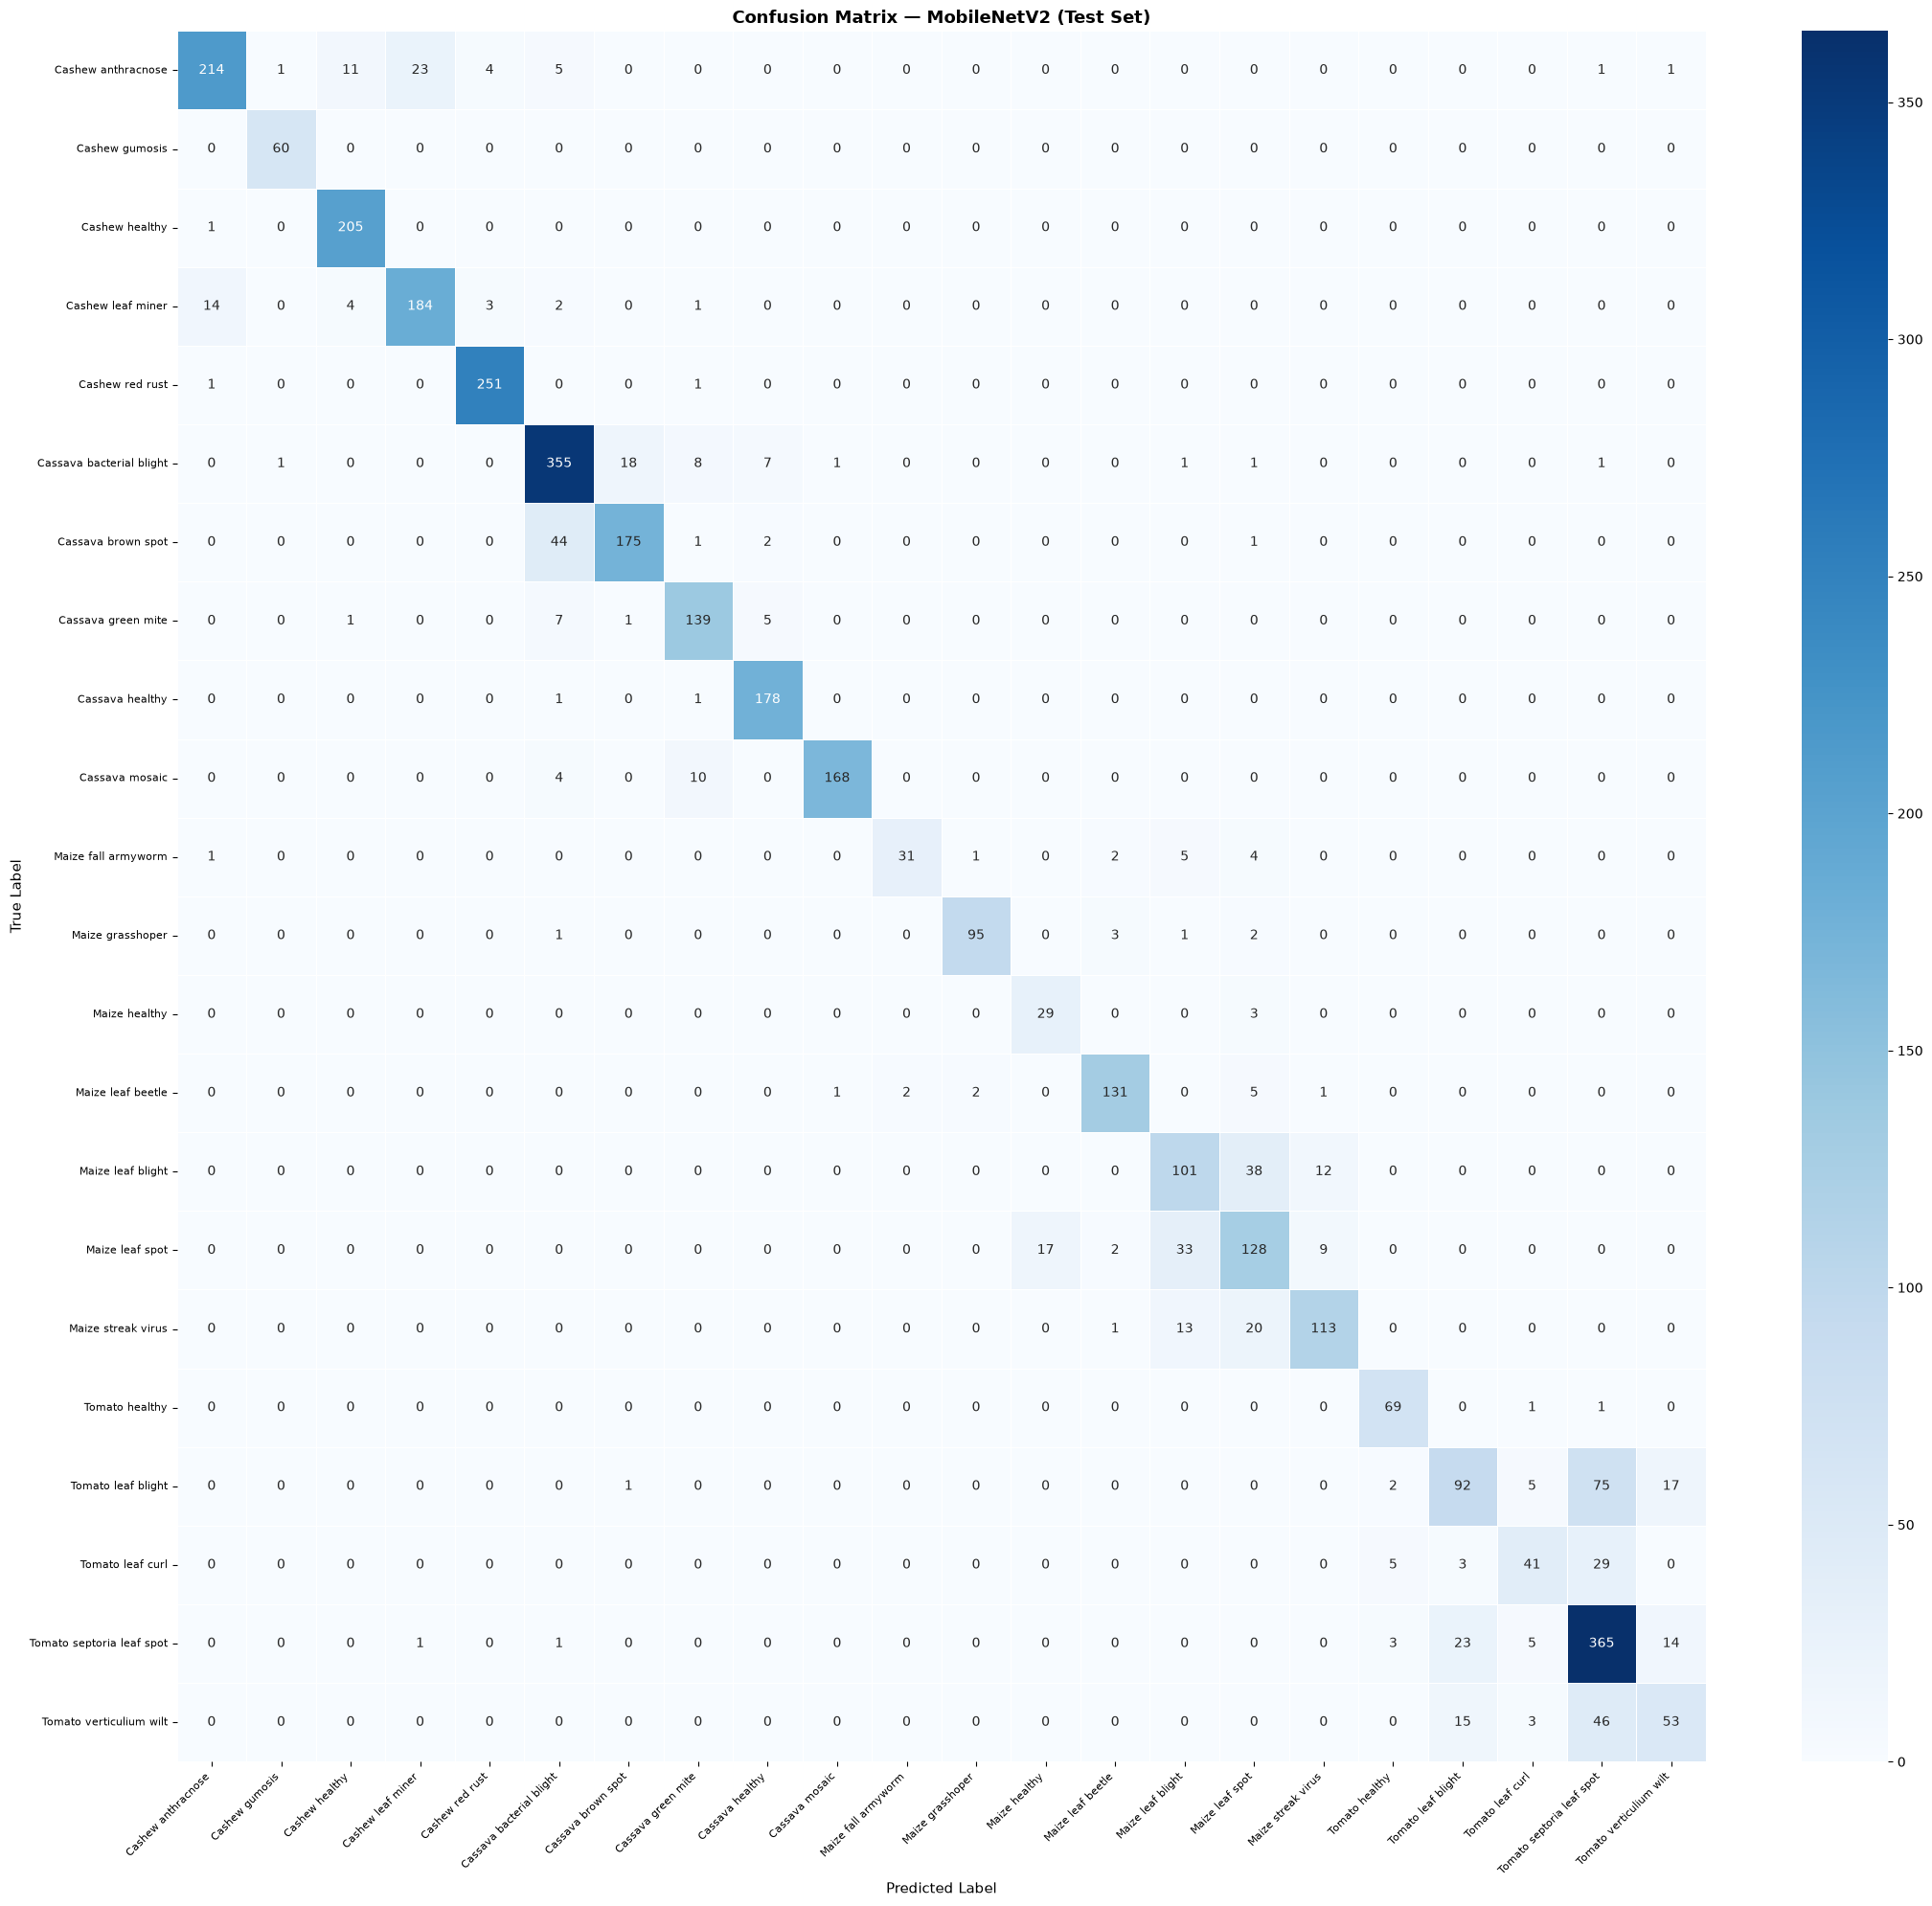

In [28]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(12, NUM_CLASSES), max(10, NUM_CLASSES - 2)))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    linewidths=0.5,
)
plt.title("Confusion Matrix — MobileNetV2 (Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label",      fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

### CELL 14 ── Per-Class Accuracy Bar Chart


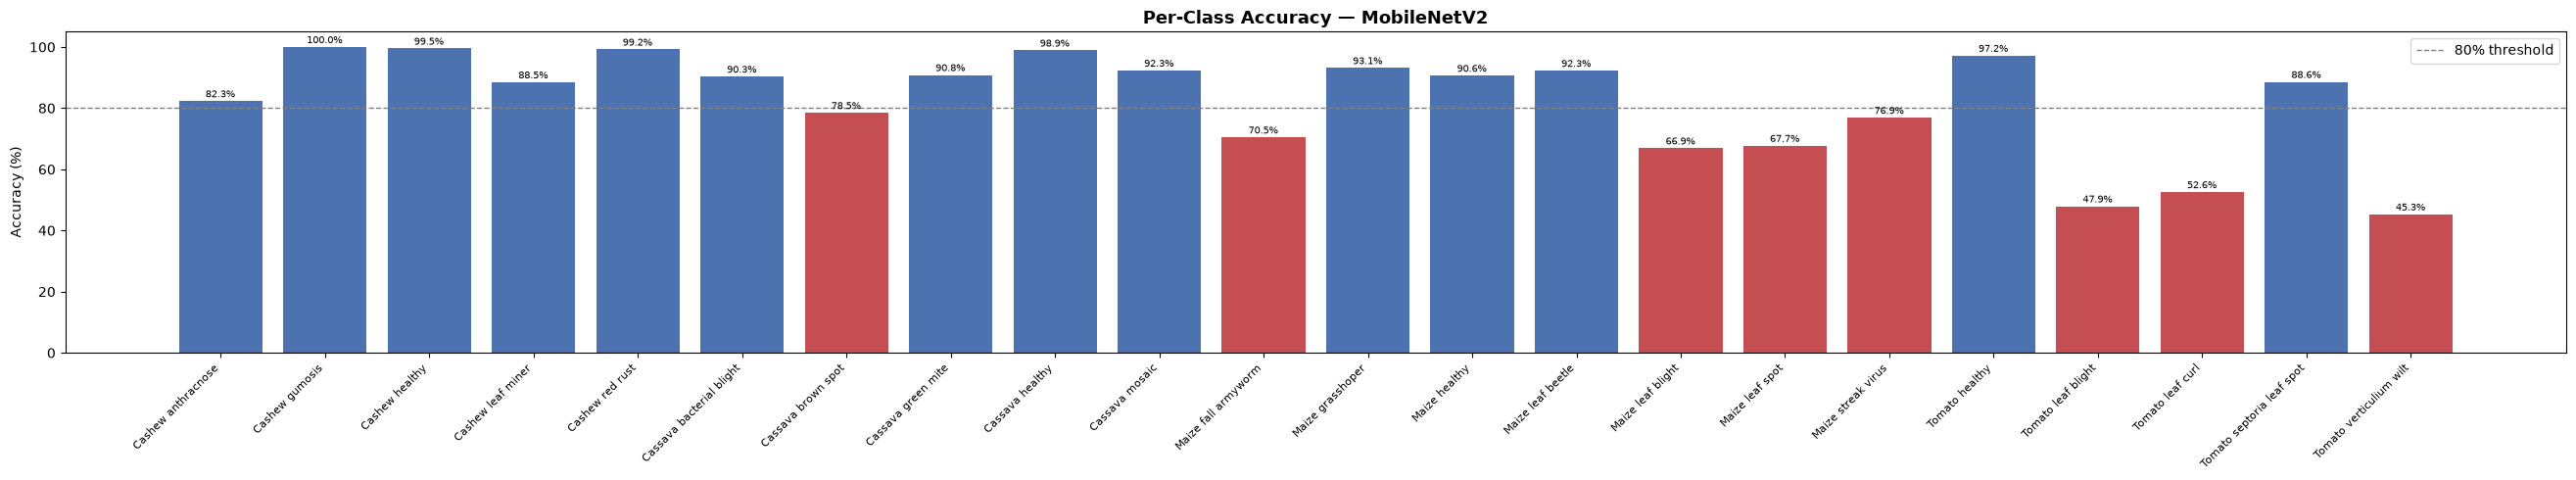

In [29]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(max(12, NUM_CLASSES * 1.2), 5))
colors = ["#4C72B0" if a >= 0.8 else "#C44E52" for a in per_class_acc]
bars = plt.bar(CLASS_NAMES, per_class_acc * 100, color=colors)
plt.axhline(y=80, color="grey", linestyle="--", linewidth=1, label="80% threshold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy — MobileNetV2", fontsize=13, fontweight="bold")
plt.legend()
for bar, acc in zip(bars, per_class_acc):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.5,
             f"{acc*100:.1f}%", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

### CELL 15 ── Sample Predictions Grid (Green = Correct, Red = Wrong)


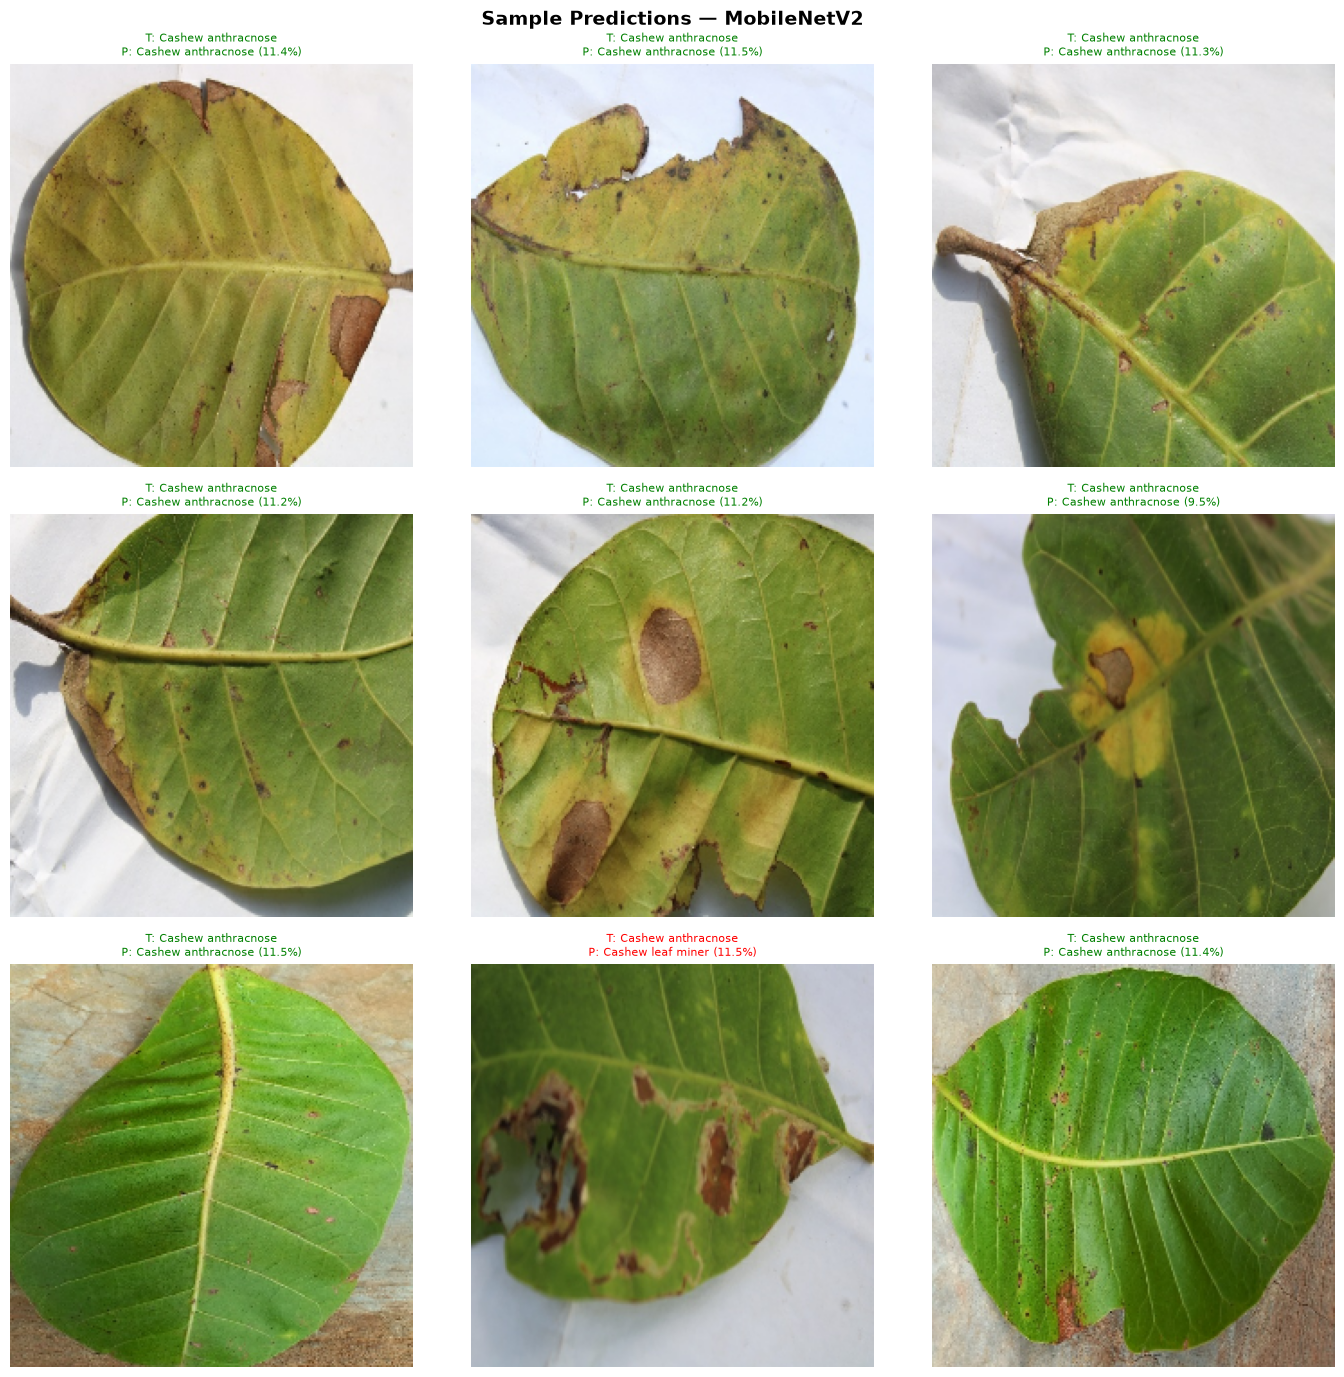

In [30]:
plt.figure(figsize=(14, 14))
plt.suptitle("Sample Predictions — MobileNetV2", fontsize=14, fontweight="bold")
for images, labels in test_ds.take(1):
    preds = np.argmax(model.predict(images, verbose=0), axis=1)
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_lbl = CLASS_NAMES[labels[i]]
        pred_lbl = CLASS_NAMES[preds[i]]
        colour   = "green" if true_lbl == pred_lbl else "red"
        conf     = np.max(tf.nn.softmax(y_prob[i]).numpy()) * 100
        plt.title(f"T: {true_lbl}\nP: {pred_lbl} ({conf:.1f}%)",
                  color=colour, fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()

### Interpretation of Image-Based Classification Results

In evaluating the sample prediction grid and confusion matrix from a digital image processing perspective:

1. **Visual Cues Leveraged by the Classifier:**
   - **Chromatic Discoloration:** Chlorotic margins and dark necrotic lesions serve as primary chromatic markers.
   - **Spatial Texture:** Powdery mildew, serpentine leaf miner tracks, and fungal spots provide distinct spatial frequency signatures.
2. **Sources of Inter-Class Confusion:**
   - **Morphological Similarity:** Early blight and leaf spots produce similar circular necrotic lesions.
   - **Environmental Artifacts:** Harsh daylight glares and deep foliage shadows can distort color and contrast.
   - **Complex Backgrounds:** Soil backgrounds and overlapping non-target vegetation introduce spurious edge responses.
3. **Academic Clarification on Evaluation vs. DIP:**
   - A **confusion matrix** evaluates categorical classification performance, not digital image processing.
   - A **whole-image classification label** indicates the diagnosis of the overall image tile; it does **not** generate pixel-level lesion boundary masks.
   - **Activation maps** show filter responses across spatial receptive fields; they do **not** constitute semantic segmentation masks.

### CELL 16 ── Save Final Model


In [32]:
model.save("MobileNetV2_Crop_Disease_Final.keras")
print("Model saved →  MobileNetV2_Crop_Disease_Final.keras")

Model saved →  MobileNetV2_Crop_Disease_Final.keras


### Digital Image Processing Summary and Case Study Findings

#### 1. Input Image Representation and Dimensions
MobileNetV2 processes standardized $224 \times 224 \times 3$ RGB digital images ($150,528$ pixel intensity values), decoded from JPEG files into numerical arrays.

#### 2. Image Transformations Applied
- **Geometric Transformations:** Horizontal and vertical reflections, affine rotation ($\pm 90^\circ$), and zoom scaling ($\pm 20\%$) enforce rotational and scale invariance against camera positioning.
- **Intensity Transformations:** Contrast adjustment ($\pm 15\%$) and brightness shifts ($\pm 10\%$) simulate changing sunlight and exposure levels.

#### 3. Pixel Intensity Preprocessing
Input tensors are scaled to $[-1.0, +1.0]$ float32 via `mobilenet_v2.preprocess_input` ($X' = X/127.5 - 1.0$), ensuring zero-centered pixel distributions aligned with pretrained ImageNet weights.

#### 4. Convolutional Feature Extraction
MobileNetV2 uses Depthwise Separable Convolutions to decouple 2D spatial filtering ($3 \times 3$ depthwise) from channel combination ($1 \times 1$ pointwise), reducing computation by $\approx 89\%$. Inverted residuals with linear bottlenecks preserve delicate symptom features.

#### 5. Relevance to Crop Disease Identification
The lightweight depthwise separable architecture delivers high classification capability while remaining efficient enough for real-time mobile and drone deployment in precision agriculture.

#### 6. Limitations of the Image Processing Approach
- **No Explicit Lesion Segmentation:** Categorizes whole image tiles rather than segmenting individual lesion perimeters.
- **Downsampling:** Bilinear downsampling to $224 \times 224$ can suppress very fine micro-lesions.
- **Background Interference:** In the absence of explicit background masking, complex soil and weed textures can influence predictions.